# Phase 1 - Measurement and Behavioural Identification

To preprocess and extract meaningful behavioural measures from the LSApp dataset
using established smartphone-use measurement procedures.

## File Imports

In [ ]:
import pandas as pd
from google.colab import drive

In [ ]:
# Connect Google Drive Folder
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Read CSV file
try:
  telemetry_df = pd.read_csv("/content/drive/My Drive/Research Thesis/lsapp.tsv.gz", sep="\t", compression="gzip")
  print("File read successfully")
except FileNotFoundError:
  print("File not found")

File read successfully


In [ ]:
telemetry_df

,lsapp.tsv,session_id,timestamp,app_name,event_type
0,0.0,1.0,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened
1,0.0,1.0,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed
2,0.0,1.0,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened
3,0.0,1.0,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed
4,0.0,1.0,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened
...,...,...,...,...,...
3658585,291.0,76247.0,2018-04-06 14:35:15,Facebook,Opened
3658586,291.0,76247.0,2018-04-06 14:35:37,Facebook,Closed
3658587,291.0,76247.0,2018-04-06 14:35:37,Facebook,Opened
3658588,291.0,76247.0,2018-04-06 14:35:52,Facebook Messenger,User Interaction


In [ ]:
# Formatting
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## The LSApp Dataset

### Overview

In [ ]:
# Shape
telemetry_df.shape

(3658590, 5)

In [ ]:
# Columns
telemetry_df.rename(columns={'lsapp.tsv': 'user_id'}, inplace=True)
telemetry_df.columns

Index(['user_id', 'session_id', 'timestamp', 'app_name', 'event_type'], dtype='object')

In [ ]:
# Data types
telemetry_df.dtypes

,0
user_id,float64
session_id,float64
timestamp,object
app_name,object
event_type,object


In [ ]:
# Data preview (head and tail)
telemetry_df

,user_id,session_id,timestamp,app_name,event_type
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened
...,...,...,...,...,...
3658585,291.00,"76,247.00",2018-04-06 14:35:15,Facebook,Opened
3658586,291.00,"76,247.00",2018-04-06 14:35:37,Facebook,Closed
3658587,291.00,"76,247.00",2018-04-06 14:35:37,Facebook,Opened
3658588,291.00,"76,247.00",2018-04-06 14:35:52,Facebook Messenger,User Interaction


In [ ]:
# Data Info
telemetry_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3658590 entries, 0 to 3658589
Data columns (total 5 columns):
 #   Column      Dtype  
---  ------      -----  
 0   user_id     float64
 1   session_id  float64
 2   timestamp   object 
 3   app_name    object 
 4   event_type  object 
dtypes: float64(2), object(3)
memory usage: 139.6+ MB


In [ ]:
# Number of Users
print(f"Number of unique users: {telemetry_df['user_id'].nunique():,}")

Number of unique users: 292


In [ ]:
# Number of Sessions
print(f"Number of unique sessions: {telemetry_df['session_id'].nunique():,}")

Number of unique sessions: 76,247


In [ ]:
# Number of Apps
print(f"Number of unique apps: {telemetry_df['app_name'].nunique():,}")

Number of unique apps: 87


In [ ]:
# Number of Event Types
print(f"Number of unique event types: {telemetry_df['event_type'].nunique():,}")

Number of unique event types: 4


In [ ]:
# Convert Timestamp Object to DateTime Object
telemetry_df['timestamp'] = pd.to_datetime(telemetry_df['timestamp'])

# Temporal coverage
print(f"Earliest timestamp: {telemetry_df['timestamp'].min()}")
print(f"Latest timestamp: {telemetry_df['timestamp'].max()}")

# Get duration of temporal coverage
duration = telemetry_df['timestamp'].max() - telemetry_df['timestamp'].min()
print(f"Duration: {duration}")

Earliest timestamp: 2017-09-09 17:16:06
Latest timestamp: 2018-05-17 08:42:29
Duration: 249 days 15:26:23


In [ ]:
# Summary table
import pandas as pd

# Mapping for the qualitative 'Purpose' and desired display types
purposes = {
    'user_id': 'Participant identifier',
    'session_id': 'LSApp-defined usage session',
    'timestamp': 'Event occurrence time',
    'app_name': 'Application involved',
    'event_type': 'Event occurring at timestamp'
}

type_map = {
    'user_id': 'integer',
    'session_id': 'integer',
    'timestamp': 'datetime',
    'app_name': 'categorical',
    'event_type': 'categorical'
}

rows = []
for col in telemetry_df.columns.tolist():
    rows.append({
        'Variable': col,
        'Data type': type_map.get(col, str(telemetry_df[col].dtype)),
        'Unique values': f"{telemetry_df[col].nunique():,}",
        'Missing': f"{telemetry_df[col].isnull().sum():,}",
        'Purpose': purposes.get(col, '')
    })

summary_table = pd.DataFrame(rows)
summary_table

,Variable,Data type,Unique values,Missing,Purpose
0,user_id,integer,292,1,Participant identifier
1,session_id,integer,"76,247",1,LSApp-defined usage session
2,timestamp,datetime,"942,582",1,Event occurrence time
3,app_name,categorical,87,1,Application involved
4,event_type,categorical,4,1,Event occurring at timestamp


### Event Types

In [ ]:
# Event Type Distribution
telemetry_df['event_type'].value_counts()

,count
event_type,
Opened,1673261
Closed,1667014
User Interaction,313829
Broken,4485


In [ ]:
# Event type disctribution in percentages
telemetry_df['event_type'].value_counts(normalize=True) * 100

,proportion
event_type,
Opened,45.74
Closed,45.56
User Interaction,8.58
Broken,0.12


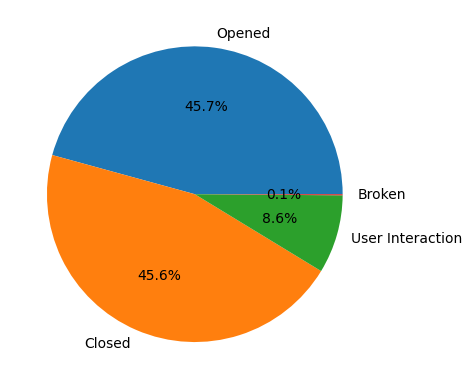

In [ ]:
# Pie Chart of Event Type Distribution usint matplotlib
import matplotlib.pyplot as plt

# Create a pie chart
plt.pie(telemetry_df['event_type'].value_counts(), labels=telemetry_df['event_type'].value_counts().index, autopct='%1.1f%%')

# Show Pie chart only
plt.show()

### User Level Participation

In [ ]:
# Events per user
events_per_user = telemetry_df.groupby('user_id').size()
events_per_user

,0
user_id,
0.00,9326
1.00,1901
2.00,1190
3.00,934
4.00,1010
...,...
287.00,1841
288.00,6
289.00,4585


In [ ]:
# Events per user description
events_per_user.rename("Events per user").describe()

,Events per user
count,292.00
mean,"12,529.41"
std,"25,094.13"
min,2.00
25%,767.75
50%,"3,220.50"
75%,"10,055.50"
max,"156,245.00"


In [ ]:
# Sessions per User
sessions_per_user = telemetry_df.groupby('user_id')['session_id'].nunique()
sessions_per_user

,session_id
user_id,
0.00,241
1.00,88
2.00,62
3.00,72
4.00,45
...,...
287.00,72
288.00,3
289.00,232


In [ ]:
# Sessions per user description
sessions_per_user.rename("Number of Sessions per User").describe()

,Number of Sessions per User
count,292.00
mean,261.12
std,484.98
min,1.00
25%,45.75
50%,95.50
75%,289.00
max,"5,153.00"


In [ ]:
# Apps per user
apps_per_user = telemetry_df.groupby('user_id')['app_name'].nunique()
apps_per_user

,app_name
user_id,
0.00,19
1.00,18
2.00,16
3.00,15
4.00,8
...,...
287.00,17
288.00,1
289.00,25


In [ ]:
# Apps per user description
apps_per_user.rename("Number of apps per user").describe()

,Number of apps per user
count,292.00
mean,16.11
std,6.48
min,1.00
25%,12.00
50%,17.00
75%,20.25
max,32.00


### Session level overview

In [ ]:
# Session event count
session_events = telemetry_df.groupby(
    ['user_id', 'session_id']
).size()
session_events.rename("Number of sessions")

user_id  session_id
0.00     1.00           80
         2.00            8
         3.00            3
         4.00           88
         5.00          104
                      ... 
291.00   76,243.00      29
         76,244.00       2
         76,245.00       4
         76,246.00       2
         76,247.00       8
Name: Number of sessions, Length: 76247, dtype: int64

In [ ]:
# Session Duration
session_duration = telemetry_df.groupby(
    ['user_id', 'session_id']
)['timestamp'].max() - telemetry_df.groupby(
    ['user_id', 'session_id']
)['timestamp'].min()
session_duration

user_id  session_id
0.00     1.00         0 days 00:03:12
         2.00         0 days 00:00:32
         3.00         0 days 00:01:51
         4.00         0 days 00:05:48
         5.00         0 days 00:02:06
                            ...      
291.00   76,243.00    0 days 00:19:38
         76,244.00    0 days 00:00:35
         76,245.00    0 days 00:09:14
         76,246.00    0 days 00:00:02
         76,247.00    0 days 00:01:37
Name: timestamp, Length: 76247, dtype: timedelta64[ns]

In [ ]:
# Session duration summary
session_duration = (
    telemetry_df.groupby(['user_id', 'session_id'])['timestamp']
      .agg(['min', 'max'])
)

session_duration['duration'] = (
    session_duration['max'] -
    session_duration['min']
).dt.total_seconds()

session_duration['duration'].describe()

,duration
count,"76,247.00"
mean,319.34
std,544.85
min,0.00
25%,9.00
50%,118.00
75%,400.00
max,"15,280.00"


In [ ]:
# Apps per session
apps_per_session = telemetry_df.groupby(
    ['user_id', 'session_id']
)['app_name'].nunique()
apps_per_session.rename("Number of apps")

user_id  session_id
0.00     1.00          1
         2.00          4
         3.00          1
         4.00          2
         5.00          2
                      ..
291.00   76,243.00     3
         76,244.00     1
         76,245.00     1
         76,246.00     1
         76,247.00     3
Name: Number of apps, Length: 76247, dtype: int64

### Application Level Usage

In [ ]:
# App frequency
app_frequency = telemetry_df['app_name'].value_counts()
app_frequency

,count
app_name,
Facebook,506209
Google Chrome,321183
Facebook Messenger,237622
Google,210108
Twitter,186339
...,...
TextNow,944
Pixlr,209
Text One,48


In [ ]:
# Top 15 app frequency
top_15_app_frequency = app_frequency.head(15)
top_15_app_frequency

,count
app_name,
Facebook,506209
Google Chrome,321183
Facebook Messenger,237622
Google,210108
Twitter,186339
Messages,157280
Instagram,126008
Reddit,123069
Gmail,107305


In [ ]:
# Number of users per app
telemetry_df.groupby('app_name')['user_id'].nunique().rename("Number of users")

,Number of users
app_name,
AOL,3
Amazon Shopping,71
Android In Call UI,61
Army Men Strike,1
Badoo,4
...,...
Words With Friends 2,10
Yahoo Mail,32
YouTube,218


In [ ]:
# Apps per session summary
apps_per_session.rename("Number of apps per session").describe()

,Number of apps per session
count,"76,247.00"
mean,2.38
std,1.66
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,17.00


### Temporal Behaviour

In [ ]:
# Events by hour
events_by_hour = telemetry_df.groupby(
    telemetry_df['timestamp'].dt.hour
).size()
events_by_hour.rename("Number of events per hour")

,Number of events per hour
timestamp,
0.00,185201
1.00,172653
2.00,160803
3.00,144461
4.00,118224
5.00,107207
6.00,97847
7.00,93369
8.00,79155


In [ ]:
# Sessions by hour
sessions_by_hour = telemetry_df.groupby(
    telemetry_df['timestamp'].dt.hour
)['session_id'].nunique()
sessions_by_hour.rename("Number of sessions per hour")

,Number of sessions per hour
timestamp,
0.00,4174
1.00,3942
2.00,3646
3.00,3264
4.00,2853
5.00,2448
6.00,1989
7.00,1807
8.00,1682


In [ ]:
# Events by day of week
days = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}

events_by_day_of_week = telemetry_df.groupby(
    telemetry_df['timestamp'].dt.dayofweek
).size().rename(index=days)

events_by_day_of_week.rename("Number of events")

,Number of events
timestamp,
Monday,534588
Tuesday,602383
Wednesday,584764
Thursday,522920
Friday,455037
Saturday,449705
Sunday,509192


In [ ]:
# Sessions by day
sessions_by_day = telemetry_df.groupby(
    telemetry_df['timestamp'].dt.dayofweek
)['session_id'].nunique().rename(index=days)

sessions_by_day.rename("Number of sessions")

,Number of sessions
timestamp,
Monday,11556
Tuesday,11310
Wednesday,11086
Thursday,10697
Friday,10398
Saturday,10815
Sunday,10733


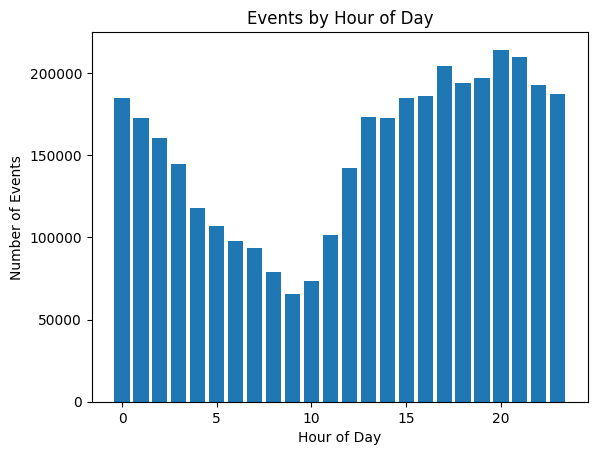

In [ ]:
# Events by Hour of day plot
plt.bar(events_by_hour.index, events_by_hour.values)

# Set labels and title
plt.xlabel('Hour of Day')
plt.ylabel('Number of Events')
plt.title('Events by Hour of Day')

# Show the plot
plt.show()

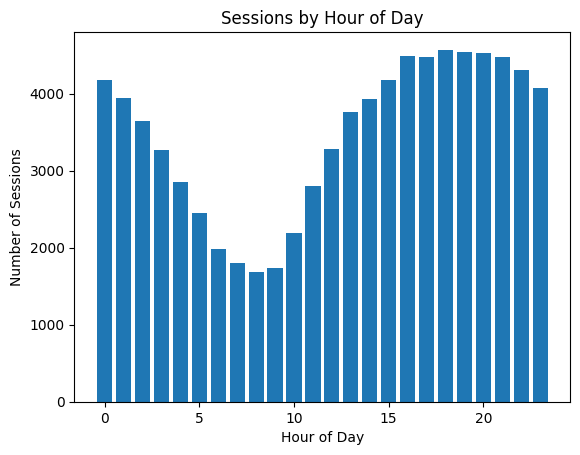

In [ ]:
# Sessions by Hour of Day plot
plt.bar(sessions_by_hour.index, sessions_by_hour.values)

# Set labels and title
plt.xlabel('Hour of Day')
plt.ylabel('Number of Sessions')
plt.title('Sessions by Hour of Day')

# Show the plot
plt.show()

In [ ]:
# Inter-event timing
df = telemetry_df.sort_values(
    ['user_id', 'session_id', 'timestamp']
)

df['inter_event_seconds'] = (
    df.groupby(['user_id', 'session_id'])['timestamp']
      .diff()
      .dt.total_seconds()
)

df['inter_event_seconds'].describe(
    percentiles=[.25, .5, .75, .9, .95, .99]
)

,inter_event_seconds
count,"3,582,342.00"
mean,6.80
std,27.90
min,0.00
25%,0.00
50%,0.00
75%,1.00
90%,9.00
95%,35.00
99%,163.00


In [ ]:
# Timestamp Duplicates Mean
df['timestamp'].duplicated().mean()

np.float64(0.7423644081463078)

In [ ]:
# Timestamp counts
timestamp_counts = df.groupby(
    ['user_id', 'session_id', 'timestamp']
).size()

timestamp_counts.rename("Number of events per timestamp").describe()

,Number of events per timestamp
count,"1,039,489.00"
mean,3.52
std,4.74
min,1.00
25%,1.00
50%,2.00
75%,4.00
max,248.00


### Open/Close Structure

In [ ]:
# Event Type Pairing
event_counts = pd.crosstab(
    [
        df['user_id'],
        df['session_id'],
        df['app_name']
    ],
    df['event_type']
)
event_counts

event_type                                      Broken  Closed  Opened  \
user_id session_id app_name                                              
0.00    1.00       Minesweeper Classic (Mines)       0      40      40   
        2.00       Gmail                             0       0       0   
                   Google                            0       2       2   
                   Google Chrome                     0       0       1   
                   Instagram                         0       1       1   
...                                                ...     ...     ...   
291.00  76,245.00  Facebook Messenger                0       2       1   
        76,246.00  Settings                          0       1       1   
        76,247.00  Facebook                          0       2       3   
                   Facebook Messenger                0       0       0   
                   Settings                          0       1       1   

event_type                                      User Interaction  
user_id session_id app_name                                       
0.00    1.00       Minesweeper Classic (Mines)                 0  
        2.00       Gmail                                       1  
                   Google                                      0  
                   Google Chrome                               0  
                   Instagram                                   0  
...                                                          ...  
291.00  76,245.00  Facebook Messenger                          1  
        76,246.00  Settings                                    0  
        76,247.00  Facebook                                    0  
                   Facebook Messenger                          1  
                   Settings                                    0  

[181837 rows x 4 columns]

In [ ]:
# App Session Counts
app_session_counts = (
    df.groupby(['user_id', 'session_id', 'app_name'])
      .size()
)

app_session_counts.rename("Number of events per app session")

user_id  session_id  app_name                   
0.00     1.00        Minesweeper Classic (Mines)    80
         2.00        Gmail                           1
                     Google                          4
                     Google Chrome                   1
                     Instagram                       2
                                                    ..
291.00   76,245.00   Facebook Messenger              4
         76,246.00   Settings                        2
         76,247.00   Facebook                        5
                     Facebook Messenger              1
                     Settings                        2
Name: Number of events per app session, Length: 181837, dtype: int64

In [ ]:
# Number of Open events per app/session
opens = (
    df[df['event_type'] == 'Opened']
    .groupby(['user_id', 'session_id', 'app_name'])
    .size()
)
opens.rename("Number of open events per app session")

user_id  session_id  app_name                   
0.00     1.00        Minesweeper Classic (Mines)    40
         2.00        Google                          2
                     Google Chrome                   1
                     Instagram                       1
         3.00        Google Chrome                   1
                                                    ..
291.00   76,244.00   Facebook Messenger              1
         76,245.00   Facebook Messenger              1
         76,246.00   Settings                        1
         76,247.00   Facebook                        3
                     Settings                        1
Name: Number of open events per app session, Length: 135270, dtype: int64

In [ ]:
# Opens description
opens.rename("Number of open events per app session").describe()

,Number of open events per app session
count,"135,270.00"
mean,12.37
std,54.75
min,1.00
25%,2.00
50%,4.00
75%,10.00
max,"8,532.00"


### Data Quality and Structure Assessment

In [ ]:
# Missing Values
telemetry_df.isna().sum()

,0
user_id,1
session_id,1
timestamp,1
app_name,1
event_type,1


In [ ]:
# Duplicate Rows and Percentage
print("Number of duplicated Rows:", telemetry_df.duplicated().sum())
print("Percentage of duplicated Rows:", telemetry_df.duplicated().mean() * 100)

Number of duplicated Rows: 2185366
Percentage of duplicated Rows: 59.73246523934084


In [ ]:
# Check for Invalid Timestamps

# Check if timestamps are monotonically increasing within each user's stream
is_monotonic_per_user = telemetry_df.groupby('user_id')['timestamp'].apply(lambda s: s.is_monotonic_increasing)

# Are all users internally sorted?
print("All users internally monotonic:", is_monotonic_per_user.all())

# Show which users have out-of-order timestamps (if any)
print(is_monotonic_per_user[~is_monotonic_per_user])

All users internally monotonic: True
Series([], Name: timestamp, dtype: bool)


## Parry and Toth Adaptation

In [ ]:
# Create a separate dataframe for preprocessing
pre_df = telemetry_df.copy()

print(f"Starting preprocessing rows: {len(pre_df):,}")
print(f"Starting preprocessing columns: {pre_df.shape[1]}")

Starting preprocessing rows: 3,658,590
Starting preprocessing columns: 5


In [ ]:
# Explicit ordering contraints
pre_df = pre_df.sort_values(
    ['user_id', 'session_id', 'timestamp']
).reset_index(drop=True)

pre_df

,user_id,session_id,timestamp,app_name,event_type
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened
...,...,...,...,...,...
3658585,291.00,"76,247.00",2018-04-06 14:35:15,Facebook,Opened
3658586,291.00,"76,247.00",2018-04-06 14:35:37,Facebook,Closed
3658587,291.00,"76,247.00",2018-04-06 14:35:37,Facebook,Opened
3658588,291.00,"76,247.00",2018-04-06 14:35:52,Facebook Messenger,User Interaction


### Step 1 — Remove unused event types and packages

    filtered_events = raw_events |>

      FILTER WHERE event_type IN [1, 15, 16, 17, 18, 26, 27];

      FILTER WHERE package_name NOT IN excluded_package_names

In [ ]:
# Event Types
pre_df['event_type'].value_counts()

,count
event_type,
Opened,1673261
Closed,1667014
User Interaction,313829
Broken,4485


In [ ]:
# Remove Broken Events
# Broken does not represent a valid application-use boundary.
pre_df = pre_df[
    pre_df['event_type'] != 'Broken'
].copy()

pre_df['event_type'].value_counts()

,count
event_type,
Opened,1673261
Closed,1667014
User Interaction,313829


In [ ]:
# Inspect null values
pre_df.isnull().sum()

,0
user_id,1
session_id,1
timestamp,1
app_name,1
event_type,1


In [ ]:
# Get Null row(s)
pre_df[pre_df['event_type'].isnull()]

,user_id,session_id,timestamp,app_name,event_type
3658589,NaN,NaN,NaT,NaN,NaN


In [ ]:
# Remove null row
pre_df = pre_df.dropna(subset=['event_type']).copy()

pre_df.isnull().sum()

,0
user_id,0
session_id,0
timestamp,0
app_name,0
event_type,0


### Step 2 — Separate session/glance events from episode events

    glance_session_events = filtered_events |>
      FILTER WHERE event_type IN [15, 16, 17, 18, 26, 27]
  
    episode_events = filtered_events |>
      FILTER WHERE event_type == 1 AND package_name != "android"

In [ ]:
# Classification of LSApp Events
pre_df['event_class'] = pre_df['event_type'].map({
    'Opened': 'episode_start',
    'Closed': 'episode_stop',
    'User Interaction': 'interaction'
})

pre_df['event_class'].value_counts()

,count
event_class,
episode_start,1673261
episode_stop,1667014
interaction,313829


In [ ]:
# Dataset Structure Display
# This is to help demacating episodes
pre_df[
    ['user_id', 'session_id', 'timestamp',
     'app_name', 'event_type', 'event_class']
].head(20)

,user_id,session_id,timestamp,app_name,event_type,event_class
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened,episode_start
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed,episode_stop
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened,episode_start
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed,episode_stop
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start
5,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop
6,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start
7,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop
8,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Opened,episode_start
9,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Closed,episode_stop


### Step 3 — Identify starts/stops and remove artefacts

    glances_sessions = glance_session_events |>
      GROUP BY user_id;
      DECLARE use_type;
      DECLARE use_state;
      IF (event_type == 15 AND (event_type[i - 1] == 18 OR event_type[i + 1] == 18)) OR
        (event_type == 16 AND (event_type[i - 1] == 17 OR event_type[i + 1] == 17)) OR
        event_type IN [16, 27]) THEN;
        use_type = "session";
      ELSE;
        use_type = "glance";
      END IF;
      IF event_type IN [15, 27] THEN;
        use_state = "start";
      ELSE IF event_type IN [16, 26] THEN;
        use_state = "stop";
      END IF;
      FILTER WHERE use_type NOT IN [17, 18];
      FILTER WHERE NOT (use_type == "glance" AND use_state == "start" AND NOT (use_type[i + 1] == "glance" & use_state[i + 1] == "stop"));
      FILTER WHERE NOT (use_type == "glance" AND use_state == "stop" AND NOT (use_type[i - 1] == "glance" & use_state[i - 1] == "start"));
      FILTER WHERE NOT (use_type == "session" AND use_state == "start" AND NOT (use_type[i + 1] == "session" & use_state[i + 1] == "stop"));
      FILTER WHERE NOT (use_type == "session" AND use_state == "stop" AND NOT (use_type[i - 1] == "session" & use_state[i - 1] == "start"));


In [ ]:
# Extract episode boundary events
boundary_df = pre_df[
    pre_df['event_class'].isin([
        'episode_start',
        'episode_stop'
    ])
].copy()

# Preserve the session-level chronological event stream.
# app_name is NOT used as a primary ordering variable.
boundary_df = boundary_df.sort_values(
    ['user_id', 'session_id', 'timestamp']
).reset_index(drop=True)

# Preserve the original position in the session-level event stream.
boundary_df['session_event_order'] = (
    boundary_df
    .groupby(['user_id', 'session_id'])
    .cumcount()
)

print(f"Boundary events: {len(boundary_df):,}")
initial_boundary_count = len(boundary_df)

boundary_df[
    ['user_id', 'session_id', 'timestamp',
     'app_name', 'event_type', 'event_class',
     'session_event_order']
].head(20)

Boundary events: 3,340,275


,user_id,session_id,timestamp,app_name,event_type,event_class,session_event_order
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened,episode_start,0
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed,episode_stop,1
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened,episode_start,2
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed,episode_stop,3
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start,4
5,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop,5
6,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start,6
7,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop,7
8,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Opened,episode_start,8
9,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Closed,episode_stop,9


In [ ]:
# Baseline boundary-event counts

print("Boundary events by class:")
print(boundary_df['event_class'].value_counts())

print("\nBoundary events by type:")
print(boundary_df['event_type'].value_counts())

Boundary events by class:
event_class
episode_start    1673261
episode_stop     1667014
Name: count, dtype: int64

Boundary events by type:
event_type
Opened    1673261
Closed    1667014
Name: count, dtype: int64


In [ ]:
# Identify exact repeated boundary events

duplicate_columns = [
    'user_id',
    'session_id',
    'app_name',
    'timestamp',
    'event_type'
]

duplicate_mask = boundary_df.duplicated(
    subset=duplicate_columns,
    keep=False
)

duplicate_boundary_df = boundary_df[
    duplicate_mask
].copy()

print(
    f"Rows belonging to duplicate boundary groups: "
    f"{len(duplicate_boundary_df):,}"
)

Rows belonging to duplicate boundary groups: 2,624,821


In [ ]:
duplicate_boundary_df.head(30)

,user_id,session_id,timestamp,app_name,event_type,event_class,session_event_order
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start,4
5,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop,5
6,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start,6
7,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop,7
16,0.00,1.00,2018-01-16 06:03:49,Minesweeper Classic (Mines),Opened,episode_start,16
17,0.00,1.00,2018-01-16 06:03:49,Minesweeper Classic (Mines),Closed,episode_stop,17
18,0.00,1.00,2018-01-16 06:03:49,Minesweeper Classic (Mines),Opened,episode_start,18
19,0.00,1.00,2018-01-16 06:03:49,Minesweeper Classic (Mines),Closed,episode_stop,19
30,0.00,1.00,2018-01-16 06:03:56,Minesweeper Classic (Mines),Opened,episode_start,30
31,0.00,1.00,2018-01-16 06:03:56,Minesweeper Classic (Mines),Closed,episode_stop,31


In [ ]:
# Number of duplicates to remove
duplicate_rows_to_remove = boundary_df.duplicated(
    subset=duplicate_columns,
    keep='first'
).sum()

print(
    f"Duplicate boundary rows to remove: "
    f"{duplicate_rows_to_remove:,}"
)

Duplicate boundary rows to remove: 2,012,993


In [ ]:
# Consolidate exact repeated boundary events
boundary_counts_before = (
    boundary_df['event_type']
    .value_counts()
    .rename('before')
)

boundary_df = boundary_df.drop_duplicates(
    subset=duplicate_columns,
    keep='first'
).reset_index(drop=True)

print(
    f"Boundary events after duplicate consolidation: "
    f"{len(boundary_df):,}"
)

Boundary events after duplicate consolidation: 1,327,282


In [ ]:
# Check for remaining duplicates
remaining_duplicates = boundary_df.duplicated(
    subset=duplicate_columns
).sum()

print(
    f"Remaining exact boundary duplicates: "
    f"{remaining_duplicates}"
)

Remaining exact boundary duplicates: 0


In [ ]:
# Before/after comparison
boundary_counts_after = (
    boundary_df['event_type']
    .value_counts()
    .rename('after')
)

boundary_comparison = pd.concat(
    [boundary_counts_before, boundary_counts_after],
    axis=1
).fillna(0)

boundary_comparison['removed'] = (
    boundary_comparison['before']
    - boundary_comparison['after']
)

boundary_comparison

,before,after,removed
event_type,,,
Opened,1673261,652859,1020402
Closed,1667014,674423,992591


In [ ]:
# Identify simultaneous Opened and Closed events
timestamp_groups = (
    boundary_df
    .groupby([
        'user_id',
        'session_id',
        'app_name',
        'timestamp'
    ])['event_type']
    .agg(set)
)

simultaneous_mask = timestamp_groups.apply(
    lambda x: {'Opened', 'Closed'}.issubset(x)
)

simultaneous_boundaries = timestamp_groups[
    simultaneous_mask
]

print(
    f"User/session/app/timestamp groups containing "
    f"both Opened and Closed: "
    f"{len(simultaneous_boundaries):,}"
)

User/session/app/timestamp groups containing both Opened and Closed: 340,433


In [ ]:
# Inspect simultaneous open and closed events
simultaneous_boundaries.head(20)

user_id  session_id  app_name                     timestamp          
0.00     1.00        Minesweeper Classic (Mines)  2018-01-16 06:01:05    {Closed, Opened}
                                                  2018-01-16 06:01:07    {Closed, Opened}
                                                  2018-01-16 06:01:08    {Closed, Opened}
                                                  2018-01-16 06:01:09    {Closed, Opened}
                                                  2018-01-16 06:03:44    {Closed, Opened}
                                                  2018-01-16 06:03:45    {Closed, Opened}
                                                  2018-01-16 06:03:47    {Closed, Opened}
                                                  2018-01-16 06:03:49    {Closed, Opened}
                                                  2018-01-16 06:03:51    {Closed, Opened}
                                                  2018-01-16 06:03:52    {Closed, Opened}
                                                  2018-01-16 06:03:53    {Closed, Opened}
                                                  2018-01-16 06:03:54    {Closed, Opened}
                                                  2018-01-16 06:03:55    {Closed, Opened}
                                                  2018-01-16 06:03:56    {Closed, Opened}
                                                  2018-01-16 06:03:58    {Closed, Opened}
                                                  2018-01-16 06:03:59    {Closed, Opened}
                                                  2018-01-16 06:04:00    {Closed, Opened}
                                                  2018-01-16 06:04:01    {Closed, Opened}
                                                  2018-01-16 06:04:02    {Closed, Opened}
                                                  2018-01-16 06:04:04    {Closed, Opened}
Name: event_type, dtype: object

In [ ]:
# Inspect simultaneous Opened/Closed events
simultaneous_records = boundary_df[
    boundary_df.set_index([
        'user_id',
        'session_id',
        'app_name',
        'timestamp'
    ]).index.isin(
        simultaneous_boundaries.index
    )
].sort_values([
    'user_id',
    'session_id',
    'timestamp',
    'app_name',
    'event_type'
])

simultaneous_records.head(30)

,user_id,session_id,timestamp,app_name,event_type,event_class,session_event_order
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed,episode_stop,1
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened,episode_start,0
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed,episode_stop,3
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened,episode_start,2
5,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,episode_stop,5
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,episode_start,4
7,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Closed,episode_stop,9
6,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Opened,episode_start,8
9,0.00,1.00,2018-01-16 06:03:44,Minesweeper Classic (Mines),Closed,episode_stop,11
8,0.00,1.00,2018-01-16 06:03:44,Minesweeper Classic (Mines),Opened,episode_start,10


In [ ]:
# Establish chronological ordering while preserving
# the session-level behavioural sequence.

boundary_df = boundary_df.sort_values(
    ['user_id', 'session_id', 'timestamp', 'app_name']
).reset_index(drop=True)

# Create a stable event order within each user/session.
# app_name is used only as a deterministic tie-breaker
# when timestamps are identical.
boundary_df['session_event_order'] = (
    boundary_df
    .groupby(['user_id', 'session_id'])
    .cumcount()
)

print("Chronological ordering established.")

boundary_df[
    ['user_id', 'session_id', 'timestamp',
     'app_name', 'event_type', 'session_event_order']
].head(20)

Chronological ordering established.


,user_id,session_id,timestamp,app_name,event_type,session_event_order
0,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened,0
1,0.00,1.00,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed,1
2,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened,2
3,0.00,1.00,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed,3
4,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened,4
5,0.00,1.00,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed,5
6,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Opened,6
7,0.00,1.00,2018-01-16 06:01:09,Minesweeper Classic (Mines),Closed,7
8,0.00,1.00,2018-01-16 06:03:44,Minesweeper Classic (Mines),Opened,8
9,0.00,1.00,2018-01-16 06:03:44,Minesweeper Classic (Mines),Closed,9


In [ ]:
# Define the unit used for app episode reconstruction.
# Episodes are reconstructed independently within each
# user-session-app combination.

episode_group_columns = [
    'user_id',
    'session_id',
    'app_name'
]

print("Episode reconstruction unit:")
print(" → ".join(episode_group_columns))

Episode reconstruction unit:
user_id → session_id → app_name


In [ ]:
# Reconstruct valid application episodes
def pair_open_close(group):
    """
    Reconstruct valid application episodes from chronological
    Opened and Closed events within one user-session-app group.
    """

    active_open = None
    episodes = []
    anomalies = []

    # Ensure chronological ordering.
    group = group.sort_values(
        ['timestamp', 'session_event_order']
    )

    for idx, row in group.iterrows():

        event = row['event_type']

        if event == 'Opened':

            if active_open is None:
                # Start a new application episode.
                active_open = row

            else:
                # Another Opened event occurred before the
                # previous episode was closed.
                anomalies.append({
                    'row_index': idx,
                    'anomaly_type': 'repeated_open',
                    'timestamp': row['timestamp']
                })

        elif event == 'Closed':

            if active_open is not None:

                # Complete the current episode.
                episodes.append({
                    'open_index': active_open.name,
                    'close_index': idx,
                    'start_time': active_open['timestamp'],
                    'end_time': row['timestamp']
                })

                active_open = None

            else:

                # No preceding Opened event is available.
                anomalies.append({
                    'row_index': idx,
                    'anomaly_type': 'unmatched_close',
                    'timestamp': row['timestamp']
                })

    # An Opened event remained without a subsequent Closed event.
    if active_open is not None:

        anomalies.append({
            'row_index': active_open.name,
            'anomaly_type': 'unmatched_open',
            'timestamp': active_open['timestamp']
        })

    return episodes, anomalies

In [ ]:
# Reconstruct application episodes for each
# user-session-app combination.

all_episodes = []
all_anomalies = []

for group_keys, group in boundary_df.groupby(
    episode_group_columns,
    sort=False
):

    # Preserve chronological order within the app stream.
    group = group.sort_values(
        ['timestamp', 'session_event_order']
    )

    episodes, anomalies = pair_open_close(group)

    # Store valid episodes.
    for episode in episodes:

        episode.update(
            dict(zip(
                episode_group_columns,
                group_keys
            ))
        )

        all_episodes.append(episode)

    # Store anomalies for audit.
    for anomaly in anomalies:

        anomaly.update(
            dict(zip(
                episode_group_columns,
                group_keys
            ))
        )

        all_anomalies.append(anomaly)


episodes_df = pd.DataFrame(all_episodes)
anomalies_df = pd.DataFrame(all_anomalies)

print(f"Valid reconstructed episodes: {len(episodes_df):,}")
print(f"Detected anomalies: {len(anomalies_df):,}")

Valid reconstructed episodes: 585,520
Detected anomalies: 156,242


In [ ]:
# Valid Episodes
episodes_df

,open_index,close_index,start_time,end_time,user_id,session_id,app_name
0,0,1,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,1.00,Minesweeper Classic (Mines)
1,2,3,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,1.00,Minesweeper Classic (Mines)
2,4,5,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,1.00,Minesweeper Classic (Mines)
3,6,7,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,1.00,Minesweeper Classic (Mines)
4,8,9,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,1.00,Minesweeper Classic (Mines)
...,...,...,...,...,...,...,...
585515,1327271,1327272,2018-04-06 12:47:28,2018-04-06 12:53:13,291.00,"76,245.00",Facebook Messenger
585516,1327273,1327274,2018-04-06 13:20:12,2018-04-06 13:20:14,291.00,"76,246.00",Settings
585517,1327275,1327276,2018-04-06 14:34:15,2018-04-06 14:34:17,291.00,"76,247.00",Settings
585518,1327277,1327278,2018-04-06 14:34:34,2018-04-06 14:35:15,291.00,"76,247.00",Facebook


In [ ]:
# Anomalies
anomalies_df

,row_index,anomaly_type,timestamp,user_id,session_id,app_name
0,68,unmatched_open,2018-01-16 06:26:26,0.00,2.00,Google Chrome
1,69,unmatched_close,2018-01-16 06:34:35,0.00,3.00,Google Chrome
2,270,unmatched_close,2018-01-16 08:33:36,0.00,6.00,Minesweeper Classic (Mines)
3,272,repeated_open,2018-01-16 08:33:37,0.00,6.00,Minesweeper Classic (Mines)
4,430,unmatched_close,2018-01-16 11:03:16,0.00,10.00,Minesweeper Classic (Mines)
...,...,...,...,...,...,...
156237,1327247,unmatched_open,2018-04-06 11:48:03,291.00,"76,242.00",Facebook Messenger
156238,1327248,unmatched_close,2018-04-06 12:04:37,291.00,"76,243.00",Facebook Messenger
156239,1327269,unmatched_open,2018-04-06 12:37:57,291.00,"76,244.00",Facebook Messenger
156240,1327270,unmatched_close,2018-04-06 12:43:59,291.00,"76,245.00",Facebook Messenger


In [ ]:
# Calculate application episode duration.

episodes_df['duration_seconds'] = (
    episodes_df['end_time']
    - episodes_df['start_time']
).dt.total_seconds()

episodes_df

,open_index,close_index,start_time,end_time,user_id,session_id,app_name,duration_seconds
0,0,1,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,1.00,Minesweeper Classic (Mines),0.00
1,2,3,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,1.00,Minesweeper Classic (Mines),0.00
2,4,5,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,1.00,Minesweeper Classic (Mines),0.00
3,6,7,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,1.00,Minesweeper Classic (Mines),0.00
4,8,9,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,1.00,Minesweeper Classic (Mines),0.00
...,...,...,...,...,...,...,...,...
585515,1327271,1327272,2018-04-06 12:47:28,2018-04-06 12:53:13,291.00,"76,245.00",Facebook Messenger,345.00
585516,1327273,1327274,2018-04-06 13:20:12,2018-04-06 13:20:14,291.00,"76,246.00",Settings,2.00
585517,1327275,1327276,2018-04-06 14:34:15,2018-04-06 14:34:17,291.00,"76,247.00",Settings,2.00
585518,1327277,1327278,2018-04-06 14:34:34,2018-04-06 14:35:15,291.00,"76,247.00",Facebook,41.00


In [ ]:
# Validate reconstructed episode durations.

print("Duration validation")
print("=" * 40)

print(
    f"Negative durations: "
    f"{(episodes_df['duration_seconds'] < 0).sum():,}"
)

print(
    f"Zero-duration episodes: "
    f"{(episodes_df['duration_seconds'] == 0).sum():,}"
)

print(
    f"Positive-duration episodes: "
    f"{(episodes_df['duration_seconds'] > 0).sum():,}"
)

print(
    f"Missing durations: "
    f"{episodes_df['duration_seconds'].isna().sum():,}"
)

Duration validation
Negative durations: 0
Zero-duration episodes: 55,073
Positive-duration episodes: 530,447
Missing durations: 0


In [ ]:
# Descriptive statistics for reconstructed episode durations.
episode_duration_summary = (
    episodes_df['duration_seconds']
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.999
        ]
    )
)

episode_duration_summary

,duration_seconds
count,"585,520.00"
mean,24.19
std,50.05
min,0.00
50%,5.00
75%,22.00
90%,68.00
95%,122.00
99%,250.00
99.9%,392.00


In [ ]:
# Episode Duration statistics in minutes
episode_duration_summary_minutes = (
    episodes_df['duration_seconds'] / 60
).describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999
    ]
)

episode_duration_summary_minutes

,duration_seconds
count,"585,520.00"
mean,0.40
std,0.83
min,0.00
50%,0.08
75%,0.37
90%,1.13
95%,2.03
99%,4.17
99.9%,6.53


In [ ]:
# Summarise episode reconstruction anomalies.

anomaly_summary = (
    anomalies_df['anomaly_type']
    .value_counts()
    .reset_index(name='count')
)

anomaly_summary

,anomaly_type,count
0,unmatched_close,88903
1,repeated_open,47850
2,unmatched_open,19489


In [ ]:
# Inspect examples of each anomaly type.

for anomaly_type in anomalies_df['anomaly_type'].unique():

    print(f"\n--- {anomaly_type} ---")

    display(
        anomalies_df[
            anomalies_df['anomaly_type'] == anomaly_type
        ].head(10)
    )


--- unmatched_open ---


,row_index,anomaly_type,timestamp,user_id,session_id,app_name
0,68,unmatched_open,2018-01-16 06:26:26,0.00,2.00,Google Chrome
8,798,unmatched_open,2018-01-16 22:43:56,0.00,31.00,Google Chrome
12,814,unmatched_open,2018-01-16 22:52:17,0.00,32.00,Phone
14,922,unmatched_open,2018-01-19 02:00:50,0.00,50.00,Google Chrome
16,1021,unmatched_open,2018-01-19 05:29:55,0.00,55.00,Google Chrome
20,1804,unmatched_open,2018-01-19 11:30:11,0.00,68.00,Clock
21,1917,unmatched_open,2018-01-19 12:00:10,0.00,70.00,Clock
47,4111,unmatched_open,2018-01-26 12:05:49,0.00,145.00,Google Chrome
125,4441,unmatched_open,2018-01-27 02:14:16,0.00,171.00,Google
156,6410,unmatched_open,2018-02-01 04:11:54,0.00,205.00,Gmail



--- unmatched_close ---


,row_index,anomaly_type,timestamp,user_id,session_id,app_name
1,69,unmatched_close,2018-01-16 06:34:35,0.00,3.00,Google Chrome
2,270,unmatched_close,2018-01-16 08:33:36,0.00,6.00,Minesweeper Classic (Mines)
4,430,unmatched_close,2018-01-16 11:03:16,0.00,10.00,Minesweeper Classic (Mines)
6,460,unmatched_close,2018-01-16 12:10:09,0.00,12.00,Clock
7,553,unmatched_close,2018-01-16 12:30:47,0.00,14.00,Clock
9,799,unmatched_close,2018-01-16 22:49:29,0.00,32.00,Google Chrome
11,813,unmatched_close,2018-01-16 22:52:17,0.00,32.00,Phone
13,880,unmatched_close,2018-01-18 22:40:35,0.00,44.00,Google Chrome
15,923,unmatched_close,2018-01-19 02:09:29,0.00,51.00,Google Chrome
18,1022,unmatched_close,2018-01-19 05:39:35,0.00,56.00,Google Chrome



--- repeated_open ---


,row_index,anomaly_type,timestamp,user_id,session_id,app_name
3,272,repeated_open,2018-01-16 08:33:37,0.00,6.00,Minesweeper Classic (Mines)
5,432,repeated_open,2018-01-16 11:03:17,0.00,10.00,Minesweeper Classic (Mines)
10,811,repeated_open,2018-01-16 22:51:41,0.00,32.00,Phone
17,1019,repeated_open,2018-01-19 05:29:48,0.00,55.00,Amazon Shopping
22,1925,repeated_open,2018-01-19 12:31:17,0.00,71.00,Clock
24,1983,repeated_open,2018-01-19 16:14:08,0.00,84.00,Minesweeper Classic (Mines)
26,2157,repeated_open,2018-01-22 07:37:04,0.00,99.00,Minesweeper Classic (Mines)
27,2162,repeated_open,2018-01-22 07:37:07,0.00,99.00,Minesweeper Classic (Mines)
29,2442,repeated_open,2018-01-22 10:05:55,0.00,103.00,Minesweeper Classic (Mines)
31,2584,repeated_open,2018-01-22 11:18:55,0.00,105.00,Minesweeper Classic (Mines)


In [ ]:
# Check that reconstructed episodes have the expected structure.
print("Episode reconstruction validation")
print("=" * 45)

print(f"Total episodes: {len(episodes_df):,}")

print(
    f"Unique users represented: "
    f"{episodes_df['user_id'].nunique():,}"
)

print(
    f"Unique sessions represented: "
    f"{episodes_df['session_id'].nunique():,}"
)

print(
    f"Unique applications represented: "
    f"{episodes_df['app_name'].nunique():,}"
)

print(
    f"Episodes with missing start time: "
    f"{episodes_df['start_time'].isna().sum():,}"
)

print(
    f"Episodes with missing end time: "
    f"{episodes_df['end_time'].isna().sum():,}"
)

print(
    f"Episodes with negative duration: "
    f"{(episodes_df['duration_seconds'] < 0).sum():,}"
)

Episode reconstruction validation
Total episodes: 585,520
Unique users represented: 291
Unique sessions represented: 58,697
Unique applications represented: 87
Episodes with missing start time: 0
Episodes with missing end time: 0
Episodes with negative duration: 0


In [ ]:
# Verify that every reconstructed episode remains
# within a single LSApp session.

episode_session_check = (
    episodes_df['start_time']
    <= episodes_df['end_time']
)

print(
    f"Episodes with start <= end: "
    f"{episode_session_check.sum():,} / {len(episodes_df):,}"
)

print(
    f"Episodes violating start <= end: "
    f"{(~episode_session_check).sum():,}"
)

Episodes with start <= end: 585,520 / 585,520
Episodes violating start <= end: 0


In [ ]:
# Step 3 Full Summary
step3_summary = pd.DataFrame({
    'Measure': [
        'Initial boundary events',
        'Exact duplicate boundary rows removed',
        'Final boundary events',
        'Simultaneous Opened/Closed groups flagged',
        'Valid reconstructed episodes',
        'Reconstruction anomalies',
        'Negative-duration episodes'
    ],
    'Count': [
        initial_boundary_count,
        duplicate_rows_to_remove,
        len(boundary_df),
        len(simultaneous_boundaries),
        len(episodes_df),
        len(anomalies_df),
        (episodes_df['duration_seconds'] < 0).sum()
    ]
})

step3_summary

,Measure,Count
0,Initial boundary events,3340275
1,Exact duplicate boundary rows removed,2012993
2,Final boundary events,1327282
3,Simultaneous Opened/Closed groups flagged,340433
4,Valid reconstructed episodes,585520
5,Reconstruction anomalies,156242
6,Negative-duration episodes,0


### Step 4 - Calculate metrics (Establish and Validate LSApp Session Structure)

      DECLARE use_end_timestamp = event_timestamp[i + 1];
      DECLARE use_duration = use_end_timestamp - event_timestamp;
    END GROUP;

Parry and Toth (2025) derive smartphone sessions from Android
screen-state and lock/unlock events. This procedure cannot be
replicated directly for LSApp because the dataset does not contain
the corresponding hardware-level event types.

Instead, LSApp provides a precomputed `session_id` based on the
dataset's sessionisation procedure. Therefore, this study retains
the existing LSApp session boundaries rather than reconstructing
them independently.

The LSApp session structure was validated during exploratory data
analysis by examining temporal gaps between consecutive events
within sessions. The maximum observed within-session gap was
300 seconds, consistent with the documented five-minute inactivity
criterion.

Consequently, `session_id` is treated as the smartphone-session
unit throughout the adapted preprocessing pipeline.

The P&T glance construct is not reconstructed because LSApp does
not contain the screen-interactivity and lock/unlock events needed
to distinguish glances from unlocked smartphone sessions. No
synthetic `glance_id` is therefore introduced at this stage.

In [ ]:
# Validate LSApp session structure

session_summary = (
    pre_df
    .groupby(['user_id', 'session_id'])
    .agg(
        session_start=('timestamp', 'min'),
        session_end=('timestamp', 'max'),
        event_count=('timestamp', 'size'),
        unique_apps=('app_name', 'nunique')
    )
    .reset_index()
)

session_summary['session_duration_seconds'] = (
    session_summary['session_end']
    - session_summary['session_start']
).dt.total_seconds()

session_summary.head()

,user_id,session_id,session_start,session_end,event_count,unique_apps,session_duration_seconds
0,0.00,1.00,2018-01-16 06:01:05,2018-01-16 06:04:17,80,1,192.00
1,0.00,2.00,2018-01-16 06:25:54,2018-01-16 06:26:26,8,4,32.00
2,0.00,3.00,2018-01-16 06:34:35,2018-01-16 06:36:26,3,1,111.00
3,0.00,4.00,2018-01-16 07:15:56,2018-01-16 07:21:44,88,2,348.00
4,0.00,5.00,2018-01-16 08:02:05,2018-01-16 08:04:11,104,2,126.00


In [ ]:
print(f"Total LSApp sessions: {len(session_summary):,}")
print(
    f"Unique users represented: "
    f"{session_summary['user_id'].nunique():,}"
)

Total LSApp sessions: 76,245
Unique users represented: 292


In [ ]:
# Validate LSApp session boundaries
#
# The LSApp sessionisation rule uses a five-minute inactivity
# threshold in combination with an Opened event.
#
# Therefore, validation focuses specifically on Opened events
# occurring more than 300 seconds after the previous event.

session_events = (
    pre_df
    .sort_values(
        ['user_id', 'session_id', 'timestamp']
    )
    .copy()
)

session_events['previous_timestamp'] = (
    session_events
    .groupby(['user_id', 'session_id'])['timestamp']
    .shift(1)
)

session_events['inter_event_gap_seconds'] = (
    session_events['timestamp']
    - session_events['previous_timestamp']
).dt.total_seconds()

# Candidate session-boundary violations
session_boundary_violations = session_events[
    (session_events['event_type'] == 'Opened') &
    (session_events['inter_event_gap_seconds'] > 300)
].copy()

print(
    f"Opened events occurring >300 seconds "
    f"after the previous event: "
    f"{len(session_boundary_violations):,}"
)

Opened events occurring >300 seconds after the previous event: 0


In [ ]:
# Check whether these candidate boundaries retained
# the same session as the preceding event.

session_boundary_violations['previous_session_id'] = (
    session_events
    .groupby('user_id')['session_id']
    .shift(1)
    .loc[session_boundary_violations.index]
)

same_session = (
    session_boundary_violations['session_id']
    ==
    session_boundary_violations['previous_session_id']
)

print(
    f"Opened events >300 seconds apart that "
    f"incorrectly retain the same session ID: "
    f"{same_session.sum():,}"
)

Opened events >300 seconds apart that incorrectly retain the same session ID: 0


In [ ]:
# Inspect any Opened events that occur >300 seconds
# after the previous event.

session_boundary_violations[
    [
        'user_id',
        'session_id',
        'timestamp',
        'previous_timestamp',
        'inter_event_gap_seconds',
        'app_name',
        'event_type'
    ]
].sort_values(
    'inter_event_gap_seconds',
    ascending=False
).head(20)

,user_id,session_id,timestamp,previous_timestamp,inter_event_gap_seconds,app_name,event_type


The supplied `session_id` values are treated as the authoritative LSApp
session boundaries. Validation is therefore performed to ensure that
each session identifier corresponds to a single user and forms a
temporally coherent sequence of events.

This validation does not reconstruct or modify the existing session
boundaries. Instead, it verifies that the inherited session structure
is suitable for use as the temporal unit for subsequent application
episode analysis.

In [ ]:
# Validate session integrity

session_integrity = (
    pre_df
    .groupby(['user_id', 'session_id'])
    .agg(
        session_start=('timestamp', 'min'),
        session_end=('timestamp', 'max'),
        event_count=('timestamp', 'size'),
        unique_users=('user_id', 'nunique'),
        unique_apps=('app_name', 'nunique')
    )
    .reset_index()
)

session_integrity['session_duration_seconds'] = (
    session_integrity['session_end']
    - session_integrity['session_start']
).dt.total_seconds()

print(
    f"Total sessions: "
    f"{len(session_integrity):,}"
)

print(
    f"Sessions containing multiple users: "
    f"{(session_integrity['unique_users'] > 1).sum():,}"
)

print(
    f"Sessions with negative duration: "
    f"{(session_integrity['session_duration_seconds'] < 0).sum():,}"
)

print(
    f"Sessions with missing start time: "
    f"{session_integrity['session_start'].isna().sum():,}"
)

print(
    f"Sessions with missing end time: "
    f"{session_integrity['session_end'].isna().sum():,}"
)

Total sessions: 76,245
Sessions containing multiple users: 0
Sessions with negative duration: 0
Sessions with missing start time: 0
Sessions with missing end time: 0


In [ ]:
# Describe LSApp session structure

session_duration_summary = (
    session_integrity['session_duration_seconds']
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

session_duration_summary

,session_duration_seconds
count,"76,245.00"
mean,319.33
std,544.85
min,0.00
50%,118.00
75%,400.00
90%,867.00
95%,"1,295.80"
99%,"2,525.00"
max,"15,280.00"


In [ ]:
# Session-level event and application statistics

session_structure_summary = session_integrity[
    [
        'event_count',
        'unique_apps',
        'session_duration_seconds'
    ]
].describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

session_structure_summary

,event_count,unique_apps,session_duration_seconds
count,"76,245.00","76,245.00","76,245.00"
mean,47.93,2.38,319.33
std,178.30,1.66,544.85
min,1.00,1.00,0.00
50%,12.00,2.00,118.00
75%,36.00,3.00,400.00
90%,102.00,5.00,867.00
95%,189.00,6.00,"1,295.80"
99%,566.56,8.00,"2,525.00"
max,"17,424.00",17.00,"15,280.00"


In [ ]:
# Establish chronological ordering within sessions

session_order_check = (
    pre_df
    .sort_values(
        ['user_id', 'session_id', 'timestamp']
    )
    .copy()
)

session_order_check['session_event_order'] = (
    session_order_check
    .groupby(['user_id', 'session_id'])
    .cumcount()
)

session_order_check[
    [
        'user_id',
        'session_id',
        'session_event_order',
        'timestamp',
        'app_name',
        'event_type'
    ]
].head(20)

,user_id,session_id,session_event_order,timestamp,app_name,event_type
0,0.00,1.00,0,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened
1,0.00,1.00,1,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed
2,0.00,1.00,2,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened
3,0.00,1.00,3,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed
4,0.00,1.00,4,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened
5,0.00,1.00,5,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed
6,0.00,1.00,6,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened
7,0.00,1.00,7,2018-01-16 06:01:08,Minesweeper Classic (Mines),Closed
8,0.00,1.00,8,2018-01-16 06:01:09,Minesweeper Classic (Mines),Opened
9,0.00,1.00,9,2018-01-16 06:01:09,Minesweeper Classic (Mines),Closed


#### Glance-Level Adaptation

Parry and Toth (2025) distinguish smartphone sessions from glances
using Android screen-state and lock/unlock events. These hardware-level
events are not available in the LSApp dataset.

Consequently, a P&T-equivalent `glance_id` cannot be derived without
introducing an unsupported operational definition. The present study
therefore does not construct a synthetic glance identifier.

The existing LSApp `session_id` is retained as the primary temporal
unit. Application episodes reconstructed in Step 3 remain nested
within these sessions.

This represents an adaptation of the P&T preprocessing framework to
the granularity of the LSApp dataset rather than a direct replication
of its hardware-event-based glance construction.

In [ ]:
# Final validation summary

step4_summary = pd.DataFrame({
    'Validation': [
        'Total LSApp sessions',
        'Opened events >300s after previous event',
        'Opened events >300s apart retaining same session',
        'Sessions containing multiple users',
        'Sessions with negative duration',
        'Sessions with missing start time',
        'Sessions with missing end time'
    ],
    'Result': [
        len(session_integrity),
        len(session_boundary_violations),
        same_session.sum(),
        (session_integrity['unique_users'] > 1).sum(),
        (session_integrity['session_duration_seconds'] < 0).sum(),
        session_integrity['session_start'].isna().sum(),
        session_integrity['session_end'].isna().sum()
    ]
})

step4_summary

,Validation,Result
0,Total LSApp sessions,76245
1,Opened events >300s after previous event,0
2,Opened events >300s apart retaining same session,0
3,Sessions containing multiple users,0
4,Sessions with negative duration,0
5,Sessions with missing start time,0
6,Sessions with missing end time,0


### Step 5 - Create session and glance IDs (Apply and Propagate Session Identifiers)
    
    DECLARE glance_id = SEQUENCE[1, n];
    IF NOT (use_type == "glance" AND use_state == "start") THEN;
      glance_id = NA;
    ENDIF;
    DECLARE glance_id = SEQUENCE[1, LENGTH(UNIQUE(glance_id))];
    DECLARE session_id = SEQUENCE[1, n];
    IF NOT (use_type == "session" AND use_state == "start") THEN;
      session_id = NA;
    ENDIF;
    DECLARE session_id = SEQUENCE[1, LENGTH(UNIQUE(session_id))];
    IF use_type == "glance" & use_state == "stop" THEN;
      glance_id = 0;
    END IF;
    IF use_type == "session" & use_state == "stop" THEN;
      session_id = 0;
    END IF

In the original Parry and Toth (2025) procedure, session and glance
identifiers are generated from the hardware-level screen-state events
identified in the preceding steps.

LSApp already provides a `session_id` for each recorded event.
Because the LSApp session structure was retained and validated in
Step 4, the existing `session_id` is used rather than reconstructing
session identifiers.

The dataset does not contain the hardware-level events required to
derive the Parry and Toth glance construct. Consequently, no
synthetic `glance_id` is introduced.

The existing `session_id` is propagated to the reconstructed
application episodes so that each episode can be analysed within
its corresponding LSApp session.

In [ ]:
# Verify session identifiers in reconstructed episodes

print("Episode columns:")
print(episodes_df.columns.tolist())

print("\nMissing session IDs:")
print(episodes_df['session_id'].isna().sum())

print("\nUnique sessions represented:")
print(episodes_df['session_id'].nunique())

print("\nTotal episodes:")
print(len(episodes_df))

Episode columns:
['open_index', 'close_index', 'start_time', 'end_time', 'user_id', 'session_id', 'app_name', 'duration_seconds']

Missing session IDs:
0

Unique sessions represented:
58697

Total episodes:
585520


In [ ]:
# Create validated session reference

session_reference = (
    pre_df[
        ['user_id', 'session_id']
    ]
    .drop_duplicates()
)

print(
    f"Unique user-session combinations: "
    f"{len(session_reference):,}"
)

print(
    f"Unique session IDs: "
    f"{session_reference['session_id'].nunique():,}"
)

Unique user-session combinations: 76,245
Unique session IDs: 76,245


In [ ]:
# Verify that every episode maps to a valid LSApp session

episode_session_check = episodes_df[
    ['user_id', 'session_id']
].drop_duplicates()

episode_session_check = episode_session_check.merge(
    session_reference.assign(session_exists=True),
    on=['user_id', 'session_id'],
    how='left'
)

missing_sessions = episode_session_check[
    episode_session_check['session_exists'].isna()
]

print(
    f"Episode sessions checked: "
    f"{len(episode_session_check):,}"
)

print(
    f"Episode sessions not found in LSApp session structure: "
    f"{len(missing_sessions):,}"
)

Episode sessions checked: 58,697
Episode sessions not found in LSApp session structure: 0


In [ ]:
# Verify that reconstructed episodes do not
# cross LSApp session boundaries.

episode_cross_session_check = (
    episodes_df
    .merge(
        pre_df[
            [
                'user_id',
                'session_id',
                'timestamp'
            ]
        ],
        left_on=[
            'user_id',
            'session_id',
            'start_time'
        ],
        right_on=[
            'user_id',
            'session_id',
            'timestamp'
        ],
        how='left'
    )
)

print(
    f"Episode start records without a matching "
    f"LSApp event: "
    f"{episode_cross_session_check['timestamp'].isna().sum():,}"
)

Episode start records without a matching LSApp event: 0


In [ ]:
# Verify that each episode has exactly one user-session assignment.

episode_session_counts = (
    episodes_df
    .groupby(['open_index', 'close_index'])
    .size()
)

print(
    f"Episodes with multiple session assignments: "
    f"{(episode_session_counts > 1).sum():,}"
)

Episodes with multiple session assignments: 0


In [ ]:
# Create a unique episode identifier
episodes_df = (
    episodes_df
    .sort_values(
        ['user_id', 'session_id', 'start_time', 'end_time', 'app_name']
    )
    .reset_index(drop=True)
)

episodes_df['episode_number'] = (
    episodes_df
    .groupby(['user_id', 'session_id'])
    .cumcount() + 1
)

episodes_df

,open_index,close_index,start_time,end_time,user_id,session_id,app_name,duration_seconds,episode_number
0,0,1,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,1.00,Minesweeper Classic (Mines),0.00,1
1,2,3,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,1.00,Minesweeper Classic (Mines),0.00,2
2,4,5,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,1.00,Minesweeper Classic (Mines),0.00,3
3,6,7,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,1.00,Minesweeper Classic (Mines),0.00,4
4,8,9,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,1.00,Minesweeper Classic (Mines),0.00,5
...,...,...,...,...,...,...,...,...,...
585515,1327271,1327272,2018-04-06 12:47:28,2018-04-06 12:53:13,291.00,"76,245.00",Facebook Messenger,345.00,1
585516,1327273,1327274,2018-04-06 13:20:12,2018-04-06 13:20:14,291.00,"76,246.00",Settings,2.00,1
585517,1327275,1327276,2018-04-06 14:34:15,2018-04-06 14:34:17,291.00,"76,247.00",Settings,2.00,1
585518,1327277,1327278,2018-04-06 14:34:34,2018-04-06 14:35:15,291.00,"76,247.00",Facebook,41.00,2


In [ ]:
print("Episode Identifier will be a composite key of (user_id, session_id, episode_number)".upper())

EPISODE IDENTIFIER WILL BE A COMPOSITE KEY OF (USER_ID, SESSION_ID, EPISODE_NUMBER)


In [ ]:
# Validate episode uniqueness
episode_key_duplicates = (
    episodes_df
    .duplicated(
        subset=['user_id', 'session_id', 'episode_number']
    )
    .sum()
)

print(
    "Duplicate composite episode identifiers:",
    episode_key_duplicates
)

unique_episode_keys = (
    episodes_df[
        ['user_id', 'session_id', 'episode_number']
    ]
    .drop_duplicates()
    .shape[0]
)

print("Total episodes:", len(episodes_df))
print("Unique composite episode keys:", unique_episode_keys)

Duplicate composite episode identifiers: 0
Total episodes: 585520
Unique composite episode keys: 585520


In [ ]:
# Validate Episode numbering
episode_number_check = (
    episodes_df
    .groupby(['user_id', 'session_id'])
    .agg(
        first_episode_number=('episode_number', 'min'),
        last_episode_number=('episode_number', 'max'),
        episode_count=('episode_number', 'size')
    )
    .reset_index()
)

sessions_not_starting_at_one = episode_number_check[
    episode_number_check['first_episode_number'] != 1
]

print(
    "Sessions not starting at episode 1:",
    len(sessions_not_starting_at_one)
)

Sessions not starting at episode 1: 0


In [ ]:
episode_number_check['numbering_is_continuous'] = (
    episode_number_check['last_episode_number']
    == episode_number_check['episode_count']
)

print(
    "Sessions with non-continuous episode numbering:",
    (~episode_number_check['numbering_is_continuous']).sum()
)

Sessions with non-continuous episode numbering: 0


In [ ]:
# Ensure absence of cross-section boundaries
episode_session_summary = (
    episodes_df
    .groupby(['user_id', 'session_id'])
    .agg(
        session_start=('start_time', 'min'),
        session_end=('end_time', 'max'),
        episode_count=('episode_number', 'count')
    )
    .reset_index()
)

episode_group_counts = (
    episodes_df
    .groupby(
        ['user_id', 'session_id', 'episode_number']
    )
    .size()
)

print(
    "Composite episode keys occurring more than once:",
    (episode_group_counts > 1).sum()
)

Composite episode keys occurring more than once: 0


In [ ]:
# Create clean episode dataset
episode_columns = [
    'user_id',
    'session_id',
    'episode_number',
    'app_name',
    'start_time',
    'end_time',
    'duration_seconds'
]

episode_data = (
    episodes_df[episode_columns]
    .sort_values(
        [
            'user_id',
            'session_id',
            'episode_number'
        ]
    )
    .reset_index(drop=True)
)

episode_data

,user_id,session_id,episode_number,app_name,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...
585515,291.00,"76,245.00",1,Facebook Messenger,2018-04-06 12:47:28,2018-04-06 12:53:13,345.00
585516,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00
585517,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00
585518,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00


In [ ]:
# Step 5 Summary
step5_summary = pd.DataFrame({
    'Validation': [
        'Reconstructed episodes',
        'Episodes with missing user_id',
        'Episodes with missing session_id',
        'Unique user-session combinations represented',
        'Episode sessions absent from LSApp',
        'Duplicate composite episode identifiers',
        'Sessions not starting at episode 1',
        'Sessions with non-continuous episode numbering',
        'Episodes with negative duration',
        'Episodes with missing start time',
        'Episodes with missing end time'
    ],
    'Result': [
        len(episode_data),
        episode_data['user_id'].isna().sum(),
        episode_data['session_id'].isna().sum(),
        episode_data[['user_id', 'session_id']].drop_duplicates().shape[0],
        len(missing_sessions),
        episode_key_duplicates,
        len(sessions_not_starting_at_one),
        (~episode_number_check['numbering_is_continuous']).sum(),
        (episode_data['duration_seconds'] < 0).sum(),
        episode_data['start_time'].isna().sum(),
        episode_data['end_time'].isna().sum()
    ]
})

step5_summary

,Validation,Result
0,Reconstructed episodes,585520
1,Episodes with missing user_id,0
2,Episodes with missing session_id,0
3,Unique user-session combinations represented,58697
4,Episode sessions absent from LSApp,0
5,Duplicate composite episode identifiers,0
6,Sessions not starting at episode 1,0
7,Sessions with non-continuous episode numbering,0
8,Episodes with negative duration,0
9,Episodes with missing start time,0


Step 5 retained the existing LSApp `session_id` structure and propagated
session membership to the reconstructed application episodes. Because
LSApp does not contain the hardware-level screen-state events required
to construct the glance identifier used by Parry and Toth (2025), no
synthetic `glance_id` was introduced.

The reconstructed episodes were chronologically ordered within each
user-session combination and assigned an `episode_number` beginning at
one for each session. The composite key `(user_id, session_id,
episode_number)` was adopted as the unique episode identifier. Validation
confirmed that episode numbering is unique, sequential, and resets at
the beginning of each session, while all reconstructed episodes remain
associated with valid LSApp user-session combinations.

The resulting `episode_data` therefore provides the validated
session-level and episode-level representation required for the next
stage of preprocessing.

### Step 6 — Merge and Prepare

    glances_sessions_episodes = episode_events |>
      DECLARE use_type = "episode";
      DECLARE use_state = "start";
      ROWBIND(glances_sessions);
      SORT(BY user_id ASC, event_timestamp ASC);
      RENAME(event_timestamp TO use_start_timestamp);
      GROUP BY user_id;
        FILTER WHERE NOT (use_type == "episode" AND use_type[i - 1] == "episode" AND package_name[i - 1] == package_name);


In [ ]:
# Prepare Interaction Events
interaction_data = (
    pre_df[
        pre_df['event_type'] == 'User Interaction'
    ][
        [
            'user_id',
            'session_id',
            'timestamp',
            'app_name',
            'event_type'
        ]
    ]
    .copy()
)

interaction_data = interaction_data.rename(
    columns={'timestamp': 'interaction_time'}
)

interaction_data

,user_id,session_id,interaction_time,app_name,event_type
80,0.00,2.00,2018-01-16 06:25:54,Gmail,User Interaction
495,0.00,8.00,2018-01-16 09:59:57,Clock,User Interaction
496,0.00,8.00,2018-01-16 09:59:57,Clock,User Interaction
497,0.00,9.00,2018-01-16 10:29:54,Clock,User Interaction
588,0.00,11.00,2018-01-16 11:59:54,Clock,User Interaction
...,...,...,...,...,...
3658571,291.00,"76,243.00",2018-04-06 12:20:28,Gmail,User Interaction
3658572,291.00,"76,243.00",2018-04-06 12:24:15,Facebook Messenger,User Interaction
3658574,291.00,"76,244.00",2018-04-06 12:38:32,Facebook Messenger,User Interaction
3658577,291.00,"76,245.00",2018-04-06 12:49:30,Facebook Messenger,User Interaction


In [ ]:
print("Total interaction events:", len(interaction_data))
print("Unique users:", interaction_data['user_id'].nunique())
print(
    "Unique user-session combinations:",
    interaction_data[['user_id', 'session_id']].drop_duplicates().shape[0]
)

Total interaction events: 313829
Unique users: 252
Unique user-session combinations: 43913


In [ ]:
# Ensure each interation is associated with a session_id
interaction_session_check = (
    interaction_data[
        ['user_id', 'session_id']
    ]
    .drop_duplicates()
    .merge(
        session_reference.assign(session_exists=True),
        on=['user_id', 'session_id'],
        how='left'
    )
)

missing_interaction_sessions = interaction_session_check[
    interaction_session_check['session_exists'].isna()
]

print(
    "Interaction session combinations not found in LSApp:",
    len(missing_interaction_sessions)
)

Interaction session combinations not found in LSApp: 0


In [ ]:
interaction_data.columns.tolist()

['user_id', 'session_id', 'interaction_time', 'app_name', 'event_type']

In [ ]:
# Create a unified chronological event stream
episode_events = (
    episode_data[
        [
            'user_id',
            'session_id',
            'episode_number',
            'app_name',
            'start_time',
            'end_time',
            'duration_seconds'
        ]
    ]
    .copy()
)

episode_events['timestamp'] = episode_events['start_time']

episode_events['event_class'] = 'episode'

episode_events

,user_id,session_id,episode_number,app_name,start_time,end_time,duration_seconds,timestamp,event_class
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,2018-01-16 06:01:05,episode
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,2018-01-16 06:01:07,episode
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,2018-01-16 06:01:08,episode
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,2018-01-16 06:01:09,episode
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,2018-01-16 06:03:44,episode
...,...,...,...,...,...,...,...,...,...
585515,291.00,"76,245.00",1,Facebook Messenger,2018-04-06 12:47:28,2018-04-06 12:53:13,345.00,2018-04-06 12:47:28,episode
585516,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00,2018-04-06 13:20:12,episode
585517,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00,2018-04-06 14:34:15,episode
585518,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00,2018-04-06 14:34:34,episode


In [ ]:
# Prepare interactions
interaction_events = (
    interaction_data
    .copy()
)

interaction_events['event_class'] = 'interaction'
interaction_events['timestamp'] = (
    interaction_events['interaction_time']
)

interaction_events['episode_number'] = pd.NA
interaction_events['start_time'] = pd.NaT
interaction_events['end_time'] = pd.NaT
interaction_events['duration_seconds'] = pd.NA

interaction_events = interaction_events[
    [
        'user_id',
        'session_id',
        'episode_number',
        'app_name',
        'timestamp',
        'event_class',
        'start_time',
        'end_time',
        'duration_seconds'
    ]
]

interaction_events

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds
80,0.00,2.00,<NA>,Gmail,2018-01-16 06:25:54,interaction,NaT,NaT,<NA>
495,0.00,8.00,<NA>,Clock,2018-01-16 09:59:57,interaction,NaT,NaT,<NA>
496,0.00,8.00,<NA>,Clock,2018-01-16 09:59:57,interaction,NaT,NaT,<NA>
497,0.00,9.00,<NA>,Clock,2018-01-16 10:29:54,interaction,NaT,NaT,<NA>
588,0.00,11.00,<NA>,Clock,2018-01-16 11:59:54,interaction,NaT,NaT,<NA>
...,...,...,...,...,...,...,...,...,...
3658571,291.00,"76,243.00",<NA>,Gmail,2018-04-06 12:20:28,interaction,NaT,NaT,<NA>
3658572,291.00,"76,243.00",<NA>,Facebook Messenger,2018-04-06 12:24:15,interaction,NaT,NaT,<NA>
3658574,291.00,"76,244.00",<NA>,Facebook Messenger,2018-04-06 12:38:32,interaction,NaT,NaT,<NA>
3658577,291.00,"76,245.00",<NA>,Facebook Messenger,2018-04-06 12:49:30,interaction,NaT,NaT,<NA>


In [ ]:
# Prepare Episode representations
episode_events = episode_events[
    [
        'user_id',
        'session_id',
        'episode_number',
        'app_name',
        'timestamp',
        'event_class',
        'start_time',
        'end_time',
        'duration_seconds'
    ]
]

episode_events

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...,...,...
585515,291.00,"76,245.00",1,Facebook Messenger,2018-04-06 12:47:28,episode,2018-04-06 12:47:28,2018-04-06 12:53:13,345.00
585516,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,episode,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00
585517,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,episode,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00
585518,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,episode,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00


In [ ]:
# Concatinate events with interaction events
session_event_stream = pd.concat(
    [
        episode_events,
        interaction_events
    ],
    ignore_index=True
)

session_event_stream

/tmp/ipykernel_1008/3026987003.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  session_event_stream = pd.concat(


,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...,...,...
899344,291.00,"76,243.00",<NA>,Gmail,2018-04-06 12:20:28,interaction,NaT,NaT,NaN
899345,291.00,"76,243.00",<NA>,Facebook Messenger,2018-04-06 12:24:15,interaction,NaT,NaT,NaN
899346,291.00,"76,244.00",<NA>,Facebook Messenger,2018-04-06 12:38:32,interaction,NaT,NaT,NaN
899347,291.00,"76,245.00",<NA>,Facebook Messenger,2018-04-06 12:49:30,interaction,NaT,NaT,NaN


In [ ]:
# Sort data chronologically
session_event_stream = (
    session_event_stream
    .sort_values(
        [
            'user_id',
            'session_id',
            'timestamp',
            'app_name'
        ]
    )
    .reset_index(drop=True)
)

session_event_stream

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...,...,...
899344,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,episode,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00
899345,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,episode,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00
899346,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,episode,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00
899347,291.00,"76,247.00",3,Facebook,2018-04-06 14:35:15,episode,2018-04-06 14:35:15,2018-04-06 14:35:37,22.00


In [ ]:
# Within session event sequences
session_event_stream['session_event_number'] = (
    session_event_stream
    .groupby(['user_id', 'session_id'])
    .cumcount() + 1
)

session_event_stream

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds,session_event_number
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,1
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,2
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,3
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,4
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,5
...,...,...,...,...,...,...,...,...,...,...
899344,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,episode,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00,1
899345,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,episode,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00,1
899346,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,episode,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00,2
899347,291.00,"76,247.00",3,Facebook,2018-04-06 14:35:15,episode,2018-04-06 14:35:15,2018-04-06 14:35:37,22.00,3


In [ ]:
# Validate merged dataset
print(
    "Missing user IDs:",
    session_event_stream['user_id'].isna().sum()
)

print(
    "Missing session IDs:",
    session_event_stream['session_id'].isna().sum()
)

Missing user IDs: 0
Missing session IDs: 0


In [ ]:
# Event classes
print(
    session_event_stream['event_class']
    .value_counts(dropna=False)
)

event_class
episode        585520
interaction    313829
Name: count, dtype: int64


In [ ]:
# Verify chronological order
session_event_order_check = (
    session_event_stream
    .sort_values(
        [
            'user_id',
            'session_id',
            'timestamp',
            'app_name'
        ]
    )
    .groupby(['user_id', 'session_id'])
    ['timestamp']
    .apply(lambda x: x.is_monotonic_increasing)
)

print(
    "Sessions with non-monotonic timestamps:",
    (~session_event_order_check).sum()
)

Sessions with non-monotonic timestamps: 0


In [ ]:
# Check if episode_number has been corrupted
episode_key_check = (
    session_event_stream[
        session_event_stream['event_class'] == 'episode'
    ]
    .groupby(
        ['user_id', 'session_id', 'episode_number']
    )
    .size()
)

print(
    "Duplicate episode keys in merged stream:",
    (episode_key_check > 1).sum()
)

Duplicate episode keys in merged stream: 0


In [ ]:
# Episodes only
episode_data.columns.tolist()

['user_id',
 'session_id',
 'episode_number',
 'app_name',
 'start_time',
 'end_time',
 'duration_seconds']

In [ ]:
# Episodes + Interactions
# session_event_stream.drop("start_time",axis=1, inplace=True)
session_event_stream.columns.tolist()

['user_id',
 'session_id',
 'episode_number',
 'app_name',
 'timestamp',
 'event_class',
 'start_time',
 'end_time',
 'duration_seconds',
 'session_event_number']

In [ ]:
# Step 6 summary
step6_summary = pd.DataFrame({
    'Validation': [
        'Episode records',
        'Interaction records',
        'Unified event records',
        'Missing user IDs',
        'Missing session IDs',
        'Interaction sessions absent from LSApp',
        'Duplicate episode identifiers',
        'Sessions with non-monotonic timestamps'
    ],
    'Result': [
        len(episode_data),
        len(interaction_data),
        len(session_event_stream),
        session_event_stream['user_id'].isna().sum(),
        session_event_stream['session_id'].isna().sum(),
        len(missing_interaction_sessions),
        (episode_key_check > 1).sum(),
        (~session_event_order_check).sum()
    ]
})

step6_summary

,Validation,Result
0,Episode records,585520
1,Interaction records,313829
2,Unified event records,899349
3,Missing user IDs,0
4,Missing session IDs,0
5,Interaction sessions absent from LSApp,0
6,Duplicate episode identifiers,0
7,Sessions with non-monotonic timestamps,0


### Step 7 - Calculate metrics

    IF use_type == "episode" THEN;
      use_end_timestamp = use_start_timestamp[i + 1];
      use_duration = use_end_timestamp - use_start_timestamp;
    END IF;

In [ ]:
# Validate episode duration

print("Episode Duration Validation")
print("=" * 40)

print(
    "Total episodes:",
    len(episode_data)
)

print(
    "Episodes with missing start time:",
    episode_data['start_time'].isna().sum()
)

print(
    "Episodes with missing end time:",
    episode_data['end_time'].isna().sum()
)

print(
    "Episodes with negative duration:",
    (episode_data['duration_seconds'] < 0).sum()
)

print(
    "Episodes with zero duration:",
    (episode_data['duration_seconds'] == 0).sum()
)

print(
    "Episodes with missing duration:",
    episode_data['duration_seconds'].isna().sum()
)

Episode Duration Validation
Total episodes: 585520
Episodes with missing start time: 0
Episodes with missing end time: 0
Episodes with negative duration: 0
Episodes with zero duration: 55073
Episodes with missing duration: 0


In [ ]:
# Episode duration statistics

episode_duration_summary = (
    episode_data['duration_seconds']
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

episode_duration_summary

,duration_seconds
count,"585,520.00"
mean,24.19
std,50.05
min,0.00
50%,5.00
75%,22.00
90%,68.00
95%,122.00
99%,250.00
max,"3,680.00"


In [ ]:
# Episode duration statistics in minutes

episode_duration_summary_minutes = (
    episode_data['duration_seconds'] / 60
).describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

episode_duration_summary_minutes

,duration_seconds
count,"585,520.00"
mean,0.40
std,0.83
min,0.00
50%,0.08
75%,0.37
90%,1.13
95%,2.03
99%,4.17
max,61.33


In [ ]:
# Cumulative application duration within sessions

session_app_metrics = (
    episode_data
    .groupby(
        [
            'user_id',
            'session_id',
            'app_name'
        ]
    )
    .agg(
        episode_count=('episode_number', 'count'),
        total_duration_seconds=('duration_seconds', 'sum'),
        mean_episode_duration_seconds=('duration_seconds', 'mean'),
        max_episode_duration_seconds=('duration_seconds', 'max')
    )
    .reset_index()
)

session_app_metrics

,user_id,session_id,app_name,episode_count,total_duration_seconds,mean_episode_duration_seconds,max_episode_duration_seconds
0,0.00,1.00,Minesweeper Classic (Mines),31,0.00,0.00,0.00
1,0.00,2.00,Google,2,10.00,5.00,5.00
2,0.00,2.00,Instagram,1,11.00,11.00,11.00
3,0.00,3.00,Google Chrome,1,51.00,51.00,51.00
4,0.00,4.00,Google Chrome,2,0.00,0.00,0.00
...,...,...,...,...,...,...,...
128850,291.00,"76,243.00",Facebook Messenger,9,832.00,92.44,517.00
128851,291.00,"76,245.00",Facebook Messenger,1,345.00,345.00,345.00
128852,291.00,"76,246.00",Settings,1,2.00,2.00,2.00
128853,291.00,"76,247.00",Facebook,2,63.00,31.50,41.00


In [ ]:
# Session-level episode metrics

session_episode_metrics = (
    episode_data
    .groupby(
        ['user_id', 'session_id']
    )
    .agg(
        episode_count=('episode_number', 'count'),
        total_episode_duration_seconds=('duration_seconds', 'sum'),
        mean_episode_duration_seconds=('duration_seconds', 'mean'),
        max_episode_duration_seconds=('duration_seconds', 'max'),
        unique_apps=('app_name', 'nunique')
    )
    .reset_index()
)

session_episode_metrics

,user_id,session_id,episode_count,total_episode_duration_seconds,mean_episode_duration_seconds,max_episode_duration_seconds,unique_apps
0,0.00,1.00,31,0.00,0.00,0.00,1
1,0.00,2.00,3,21.00,7.00,11.00,2
2,0.00,3.00,1,51.00,51.00,51.00,1
3,0.00,4.00,36,1.00,0.03,1.00,2
4,0.00,5.00,39,0.00,0.00,0.00,2
...,...,...,...,...,...,...,...
58692,291.00,"76,242.00",9,251.00,27.89,75.00,3
58693,291.00,"76,243.00",10,849.00,84.90,517.00,2
58694,291.00,"76,245.00",1,345.00,345.00,345.00,1
58695,291.00,"76,246.00",1,2.00,2.00,2.00,1


In [ ]:
# Reconcile episode counts

episode_count_check = (
    session_episode_metrics['episode_count'].sum()
)

print(
    "Episodes in episode_data:",
    len(episode_data)
)

print(
    "Episodes represented in session metrics:",
    episode_count_check
)

print(
    "Episode count difference:",
    len(episode_data) - episode_count_check
)

Episodes in episode_data: 585520
Episodes represented in session metrics: 585520
Episode count difference: 0


In [ ]:
# Step 7 Summary

step7_summary = pd.DataFrame({
    'Metric': [
        'Total reconstructed episodes',
        'Episodes with missing start time',
        'Episodes with missing end time',
        'Episodes with missing duration',
        'Episodes with negative duration',
        'Episodes with zero duration',
        'Unique user-session combinations',
        'Session-level episode records',
        'Session-app metric records'
    ],
    'Result': [
        len(episode_data),
        episode_data['start_time'].isna().sum(),
        episode_data['end_time'].isna().sum(),
        episode_data['duration_seconds'].isna().sum(),
        (episode_data['duration_seconds'] < 0).sum(),
        (episode_data['duration_seconds'] == 0).sum(),
        episode_data[
            ['user_id', 'session_id']
        ].drop_duplicates().shape[0],
        len(session_episode_metrics),
        len(session_app_metrics)
    ]
})

step7_summary

,Metric,Result
0,Total reconstructed episodes,585520
1,Episodes with missing start time,0
2,Episodes with missing end time,0
3,Episodes with missing duration,0
4,Episodes with negative duration,0
5,Episodes with zero duration,55073
6,Unique user-session combinations,58697
7,Session-level episode records,58697
8,Session-app metric records,128855


### Step 8 - Apply glance and session IDs

    FILL_DOWN(glance_id);
    FILL_DOWN(session_id);
    IF use_type == "episode" AND session_id == 0 AND glance_id == 0 THEN;
      session_id = NA;
      glance_id = NA;
    END IF;

In [ ]:
# Validate session identifiers

print("Session Identifier Validation")
print("=" * 40)

print("Missing user IDs:",
      episode_data['user_id'].isna().sum())

print("Missing session IDs:",
      episode_data['session_id'].isna().sum())

print(
    "Unique user-session combinations:",
    episode_data[
        ['user_id', 'session_id']
    ].drop_duplicates().shape[0]
)

print(
    "Total episodes:",
    len(episode_data)
)

Session Identifier Validation
Missing user IDs: 0
Missing session IDs: 0
Unique user-session combinations: 58697
Total episodes: 585520


In [ ]:
# Verify episode-to-session membership

episode_session_validation = (
    episode_data[
        ['user_id', 'session_id']
    ]
    .drop_duplicates()
    .merge(
        session_reference.assign(session_exists=True),
        on=['user_id', 'session_id'],
        how='left'
    )
)

invalid_episode_sessions = (
    episode_session_validation[
        episode_session_validation['session_exists'].isna()
    ]
)

print(
    "Episode sessions not found in LSApp:",
    len(invalid_episode_sessions)
)

Episode sessions not found in LSApp: 0


In [ ]:
# Validate session-local episode numbering

episode_number_validation = (
    episode_data
    .groupby(['user_id', 'session_id'])
    .agg(
        first_episode=('episode_number', 'min'),
        last_episode=('episode_number', 'max'),
        episode_count=('episode_number', 'size')
    )
    .reset_index()
)

episode_number_validation['continuous'] = (
    episode_number_validation['last_episode']
    ==
    episode_number_validation['episode_count']
)

print(
    "Sessions not starting at episode 1:",
    (
        episode_number_validation['first_episode'] != 1
    ).sum()
)

print(
    "Sessions with non-continuous episode numbering:",
    (
        ~episode_number_validation['continuous']
    ).sum()
)

Sessions not starting at episode 1: 0
Sessions with non-continuous episode numbering: 0


In [ ]:
chronology_check = (
    episode_data
    .sort_values(
        ['user_id', 'session_id', 'episode_number']
    )
    .copy()
)

chronology_check['previous_start_time'] = (
    chronology_check
    .groupby(['user_id', 'session_id'])['start_time']
    .shift(1)
)

chronology_check['chronology_violation'] = (
    chronology_check['start_time']
    < chronology_check['previous_start_time']
)

print(
    "Episodes starting before the previous episode:",
    chronology_check['chronology_violation'].sum()
)

same_app_check = (
    episode_data
    .sort_values(
        ['user_id', 'session_id', 'app_name', 'start_time', 'end_time']
    )
    .copy()
)

same_app_check['previous_end_time'] = (
    same_app_check
    .groupby(['user_id', 'session_id', 'app_name'])['end_time']
    .shift(1)
)

same_app_check['overlap'] = (
    same_app_check['start_time']
    < same_app_check['previous_end_time']
)

print(
    "Overlapping episodes within the same app:",
    same_app_check['overlap'].sum()
)

Episodes starting before the previous episode: 0
Overlapping episodes within the same app: 0


In [ ]:
# Validate composite episode identifier

duplicate_episode_keys = (
    episode_data
    .duplicated(
        subset=[
            'user_id',
            'session_id',
            'episode_number'
        ]
    )
    .sum()
)

print(
    "Duplicate composite episode keys:",
    duplicate_episode_keys
)

Duplicate composite episode keys: 0


In [ ]:
# Step 8 Summary

step8_summary = pd.DataFrame({
    'Validation': [
        'Missing user IDs',
        'Missing session IDs',
        'Invalid episode-session mappings',
        'Sessions not starting at episode 1',
        'Non-continuous episode numbering',
        'Chronology violations',
        'Duplicate composite episode keys',
        'Glance identifier'
    ],
    'Result': [
        episode_data['user_id'].isna().sum(),
        episode_data['session_id'].isna().sum(),
        len(invalid_episode_sessions),
        (
            episode_number_validation['first_episode'] != 1
        ).sum(),
        (
            ~episode_number_validation['continuous']
        ).sum(),
        chronology_check['chronology_violation'].sum(),
        duplicate_episode_keys,
        'Not reconstructed — unavailable in LSApp'
    ]
})

step8_summary

,Validation,Result
0,Missing user IDs,0
1,Missing session IDs,0
2,Invalid episode-session mappings,0
3,Sessions not starting at episode 1,0
4,Non-continuous episode numbering,0
5,Chronology violations,0
6,Duplicate composite episode keys,0
7,Glance identifier,Not reconstructed — unavailable in LSApp


#### Glance Identifier Adaptation

The original preprocessing procedure applies both session and glance identifiers using Android screen-state events. LSApp does not provide the corresponding screen-interactivity, lock, unlock, startup, or shutdown events required to reconstruct these glance boundaries. Therefore, the glance layer was not artificially reconstructed. The existing LSApp session_id was retained as the highest available temporal grouping, while application episodes were identified using the composite key (user_id, session_id, episode_number). This preserves the temporal structure supported by the dataset without introducing unsupported behavioural identifiers.

### Step 9 - Cleansing

      FILTER WHERE NOT (use_type == "episode" AND NOT (use_type[i + 1] == "episode" OR (use_type[i + 1] IN ["smartphone", "glance"] & use_state[i + 1] == "stop")));
      FILTER WHERE use_state != "stop";
      FILTER WHERE NOT (glance_id == NA AND session_id == NA);
    END GROUP

In [ ]:
# Identify invalid reconstructed episodes

invalid_episode_mask = (
    episode_data['user_id'].isna()
    | episode_data['session_id'].isna()
    | episode_data['start_time'].isna()
    | episode_data['end_time'].isna()
    | episode_data['duration_seconds'].isna()
    | (episode_data['duration_seconds'] < 0)
    | episode_data['episode_number'].isna()
)

invalid_episodes = episode_data[invalid_episode_mask].copy()

print("Invalid episodes identified:", len(invalid_episodes))

Invalid episodes identified: 0


In [ ]:
# Remove invalid reconstructed episodes

episode_data_clean = (
    episode_data.loc[~invalid_episode_mask]
    .copy()
    .reset_index(drop=True)
)

print("Episodes before cleansing:", len(episode_data))
print("Episodes after cleansing:", len(episode_data_clean))
print("Episodes removed:", len(episode_data) - len(episode_data_clean))

Episodes before cleansing: 585520
Episodes after cleansing: 585520
Episodes removed: 0


In [ ]:
# Quantify zero-duration episodes

zero_duration_episodes = episode_data_clean[
    episode_data_clean['duration_seconds'] == 0
].copy()

print("Zero-duration episodes:", len(zero_duration_episodes))
print(
    "Percentage of episodes:",
    round(
        len(zero_duration_episodes) / len(episode_data_clean) * 100,
        3
    ),
    "%"
)

Zero-duration episodes: 55073
Percentage of episodes: 9.406 %


In [ ]:
zero_duration_episodes

,user_id,session_id,episode_number,app_name,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...
585477,291.00,"76,231.00",4,Facebook Messenger,2018-04-06 05:50:58,2018-04-06 05:50:58,0.00
585479,291.00,"76,231.00",6,Facebook,2018-04-06 05:51:45,2018-04-06 05:51:45,0.00
585480,291.00,"76,232.00",1,Facebook Messenger,2018-04-06 06:18:54,2018-04-06 06:18:54,0.00
585482,291.00,"76,232.00",3,Facebook,2018-04-06 06:19:39,2018-04-06 06:19:39,0.00


In [ ]:
# Validate User Interaction events

interaction_events = session_event_stream[
    session_event_stream['event_class'] == 'interaction'
].copy()

episode_events = session_event_stream[
    session_event_stream['event_class'] == 'episode'
].copy()

print("Interaction events:", len(interaction_events))
print("Episode events:", len(episode_events))
print(
    "Interactions missing timestamp:",
    interaction_events['timestamp'].isna().sum()
)

print(
    "Interactions incorrectly assigned episode numbers:",
    interaction_events['episode_number'].notna().sum()
)

print(
    "Interactions with artificial durations:",
    interaction_events['duration_seconds'].notna().sum()
)

Interaction events: 313829
Episode events: 585520
Interactions missing timestamp: 0
Interactions incorrectly assigned episode numbers: 0
Interactions with artificial durations: 0


In [ ]:
# Validate episode-session integrity

clean_episode_sessions = (
    episode_data_clean[
        ['user_id', 'session_id']
    ]
    .drop_duplicates()
)

clean_episode_session_check = (
    clean_episode_sessions
    .merge(
        session_reference.assign(session_exists=True),
        on=['user_id', 'session_id'],
        how='left'
    )
)

invalid_clean_sessions = clean_episode_session_check[
    clean_episode_session_check['session_exists'].isna()
]

print(
    "Episodes mapped to non-existent LSApp sessions:",
    len(invalid_clean_sessions)
)

Episodes mapped to non-existent LSApp sessions: 0


In [ ]:
# Validate composite episode identifiers

duplicate_episode_keys = (
    episode_data_clean
    .duplicated(
        subset=[
            'user_id',
            'session_id',
            'episode_number'
        ]
    )
    .sum()
)

print(
    "Duplicate composite episode keys:",
    duplicate_episode_keys
)

Duplicate composite episode keys: 0


In [ ]:
# Final session event stream validation

print("Total session events:", len(session_event_stream))

print("\nEvent-class counts:")
print(
    session_event_stream['event_class']
    .value_counts(dropna=False)
)

print("\nMissing user IDs:",
      session_event_stream['user_id'].isna().sum())

print("Missing session IDs:",
      session_event_stream['session_id'].isna().sum())

print("Missing timestamps:",
      session_event_stream['timestamp'].isna().sum())

Total session events: 899349

Event-class counts:
event_class
episode        585520
interaction    313829
Name: count, dtype: int64

Missing user IDs: 0
Missing session IDs: 0
Missing timestamps: 0


In [ ]:
stream_sessions = (
    session_event_stream[
        ['user_id', 'session_id']
    ]
    .drop_duplicates()
)

stream_session_check = (
    stream_sessions
    .merge(
        session_reference.assign(session_exists=True),
        on=['user_id', 'session_id'],
        how='left'
    )
)

invalid_stream_sessions = stream_session_check[
    stream_session_check['session_exists'].isna()
]

print(
    "Session-event records mapped to invalid sessions:",
    len(invalid_stream_sessions)
)

Session-event records mapped to invalid sessions: 0


In [ ]:
# Final cleansing summary

step9_summary = pd.DataFrame({
    'Validation': [
        'Episodes before cleansing',
        'Invalid episodes removed',
        'Episodes after cleansing',
        'Zero-duration episodes',
        'Duplicate composite episode keys',
        'Episodes mapped to invalid sessions',
        'Total session-event records',
        'Episode events in session stream',
        'Interaction events in session stream',
        'Session-event records with missing timestamps',
        'Session-event records mapped to invalid sessions'
    ],
    'Result': [
        len(episode_data),
        len(invalid_episodes),
        len(episode_data_clean),
        len(zero_duration_episodes),
        duplicate_episode_keys,
        len(invalid_clean_sessions),
        len(session_event_stream),
        len(episode_events),
        len(interaction_events),
        session_event_stream['timestamp'].isna().sum(),
        len(invalid_stream_sessions)
    ]
})

step9_summary

,Validation,Result
0,Episodes before cleansing,585520
1,Invalid episodes removed,0
2,Episodes after cleansing,585520
3,Zero-duration episodes,55073
4,Duplicate composite episode keys,0
5,Episodes mapped to invalid sessions,0
6,Total session-event records,899349
7,Episode events in session stream,585520
8,Interaction events in session stream,313829
9,Session-event records with missing timestamps,0


In [ ]:
# Final episode-level dataset

episode_data_final = (
    episode_data_clean
    .sort_values(
        ['user_id', 'session_id', 'episode_number']
    )
    .reset_index(drop=True)
)

print("Final episode dataset:", episode_data_final.shape)

Final episode dataset: (585520, 7)


In [ ]:
# Rebuild the final episode event representation

final_episode_events = episode_data_final.copy()

final_episode_events['timestamp'] = (
    final_episode_events['start_time']
)

# final_episode_events['event_type'] = 'Episode'
final_episode_events['event_class'] = 'episode'

final_episode_events = final_episode_events[
    [
        'user_id',
        'session_id',
        'episode_number',
        'app_name',
        'timestamp',
        # 'event_type',
        'event_class',
        'start_time',
        'end_time',
        'duration_seconds'
    ]
]

final_episode_events

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00
...,...,...,...,...,...,...,...,...,...
585515,291.00,"76,245.00",1,Facebook Messenger,2018-04-06 12:47:28,episode,2018-04-06 12:47:28,2018-04-06 12:53:13,345.00
585516,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,episode,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00
585517,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,episode,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00
585518,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,episode,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00


In [ ]:
# Final unified session event stream

session_event_stream_final = pd.concat(
    [
        final_episode_events,
        interaction_events[
            [
                'user_id',
                'session_id',
                'episode_number',
                'app_name',
                'timestamp',
                # 'event_type',
                'event_class',
                'start_time',
                'end_time',
                'duration_seconds'
            ]
        ]
    ],
    ignore_index=True
)

session_event_stream_final = (
    session_event_stream_final
    .sort_values(
        ['user_id', 'session_id', 'timestamp', 'app_name']
    )
    .reset_index(drop=True)
)

session_event_stream_final['session_event_number'] = (
    session_event_stream_final
    .groupby(['user_id', 'session_id'])
    .cumcount() + 1
)

session_event_stream_final

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds,session_event_number
0,0.00,1.00,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,episode,2018-01-16 06:01:05,2018-01-16 06:01:05,0.00,1
1,0.00,1.00,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,episode,2018-01-16 06:01:07,2018-01-16 06:01:07,0.00,2
2,0.00,1.00,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,episode,2018-01-16 06:01:08,2018-01-16 06:01:08,0.00,3
3,0.00,1.00,4,Minesweeper Classic (Mines),2018-01-16 06:01:09,episode,2018-01-16 06:01:09,2018-01-16 06:01:09,0.00,4
4,0.00,1.00,5,Minesweeper Classic (Mines),2018-01-16 06:03:44,episode,2018-01-16 06:03:44,2018-01-16 06:03:44,0.00,5
...,...,...,...,...,...,...,...,...,...,...
899344,291.00,"76,246.00",1,Settings,2018-04-06 13:20:12,episode,2018-04-06 13:20:12,2018-04-06 13:20:14,2.00,1
899345,291.00,"76,247.00",1,Settings,2018-04-06 14:34:15,episode,2018-04-06 14:34:15,2018-04-06 14:34:17,2.00,1
899346,291.00,"76,247.00",2,Facebook,2018-04-06 14:34:34,episode,2018-04-06 14:34:34,2018-04-06 14:35:15,41.00,2
899347,291.00,"76,247.00",3,Facebook,2018-04-06 14:35:15,episode,2018-04-06 14:35:15,2018-04-06 14:35:37,22.00,3


The reconstructed LSApp application episodes were subjected to final structural cleansing and validation. Episodes with missing identifiers, missing temporal boundaries, missing durations, or negative durations were identified and excluded where applicable. Zero-duration episodes were retained and quantified rather than removed automatically, as they represent valid Opened–Closed observations with identical timestamps. User Interaction events were retained as timestamped point events and were not assigned artificial durations or converted into application episodes. The final datasets preserve the original LSApp session identifiers and maintain the distinction between interval-based application episodes and point-based interaction events. Because LSApp does not contain the Android screen-state events required to reconstruct P&T-style glance identifiers, no unsupported glance-level cleansing was applied.

In [ ]:
session_event_stream_final[
    (session_event_stream_final['user_id'] == 0) &
    (session_event_stream_final['session_id'] == 28)
]

,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds,session_event_number
368,0.00,28.00,1,Google,2018-01-16 21:47:58,episode,2018-01-16 21:47:58,2018-01-16 21:48:09,11.00,1
369,0.00,28.00,<NA>,YouTube,2018-01-16 21:48:02,interaction,NaT,NaT,NaN,2
370,0.00,28.00,<NA>,Maps,2018-01-16 21:48:06,interaction,NaT,NaT,NaN,3
371,0.00,28.00,2,Google,2018-01-16 21:48:39,episode,2018-01-16 21:48:39,2018-01-16 21:48:43,4.00,4


In [ ]:
session_event_stream_final.to_excel("/content/drive/My Drive/Research Thesis/lsapp_final.xlsx", index=False)

In [ ]:
session_event_stream_final.columns.tolist()

['user_id',
 'session_id',
 'episode_number',
 'app_name',
 'timestamp',
 'event_class',
 'start_time',
 'end_time',
 'duration_seconds',
 'session_event_number']